{'weight': 78, 'height': 1.82, 'bmi': 23.55, 'category': 'Normal'}


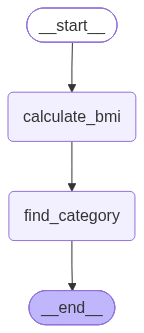

In [33]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict

# langgrapgh workflow step 1 is to define state
class BMIState(TypedDict):
    
    weight: float
    height: float
    bmi: float
    category:str
#define graph
graph = StateGraph(BMIState)

def calculate_bmi(state: BMIState) -> BMIState:
    weight = state['weight']
    height = state['height']
    bmi = weight/(height**2)
    state['bmi'] = round(bmi, 2)
    return state


def bmi_categories(state: BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        state['category'] = "underweight"
  
    elif bmi > 18.5 and bmi <= 24:
        state['category'] = 'Normal'
     
    elif bmi > 24 and bmi <= 30:
        state['category'] = 'over weight' 
    else:
        state['category'] = "obese"
    return state

#add nodes to the graph


graph.add_node("calculate_bmi",calculate_bmi)
graph.add_node("find_category",bmi_categories)

##adding edges

graph.add_edge(START,"calculate_bmi")
graph.add_edge("calculate_bmi" , "find_category")
graph.add_edge("find_category" , END)

# lets compile the graph

workflow = graph.compile()
initial_state = {'weight': 78, 'height': 1.82}
final_state = workflow.invoke(initial_state)
print(final_state)

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())